# 02 · Weather honesty: which archived forecasts could a forecaster really have had?

**Question.** A day-ahead grid forecast issued on day D−1 may only use weather *forecasts* that were published before the issue time. Which of Open-Meteo's archives give us that, from which dates, and how do we pick the right one automatically?

**Short answer.**
- Only the **Previous Runs API with the `_previous_day2` suffix** (a 48–53 h lead) is honest for every hour of day D at a D−1 issue time. The **Historical Forecast** API and the unsuffixed Previous Runs output are the same series: each hour is taken from a run started 0–5 h earlier, which is close to a nowcast and leaks.
- All three variables we need (temperature, solar radiation, 100 m wind) exist as `_previous_day2` only from **2024-02-17**, so **2024-03-01** is the clean start. Temperature alone goes back to 2021-03-25, with a three-week gap in January 2024.
- `gridpilot.data.weather.safe_previous_day` picks, for each target hour, the shortest lead that was already published. For PACE at 10:00 MT on D−1 it allows `_previous_day1` for local hours 00–03 of D and requires `_previous_day2` for the rest.

**How to read this notebook.** Values are *forecast* (archived numerical weather prediction output, Open-Meteo, CC BY 4.0: "Weather data by Open-Meteo.com"). The profile behind it is [`docs/data-profile/grid.md` §9](../docs/data-profile/grid.md#9-archived-weather-forecasts-open-meteo).

**Seal.** Statistics use hours before 2025-11-01Z only (`gridpilot.data.weather.load` drops the sealed window by default). §5 shows the sealed window as row and null counts only.

## 0. Inputs (pinned)

The Open-Meteo manifest was still growing when this notebook was written: a background download of secondary points (Previous Runs P2) is adding files to other point directories. So this notebook pins its own inputs: it hashes every file it reads now, and checks the same hashes again at the end (§6).

In [1]:
import json
from datetime import UTC, date, datetime, timedelta
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import numpy as np
import polars as pl

from gridpilot import notebook as nb
from gridpilot.data import weather as W
from gridpilot.splits import TEST_START

nb.setup()
P1 = [p.point_id for p in W.POINTS if p.priority == 1]
PR, HF = W.RAW_OM_DIR / "previous-runs" / "best_match", W.RAW_OM_DIR / "historical-forecast" / "best_match"
PROBE = W.RAW_OM_DIR / "_probe" / "coverage_probe.json"
files = sorted([PROBE, *(f for p in P1 for f in (PR / p).glob("*.json")),
                *(f for d in sorted(HF.iterdir()) for f in d.glob("*.json"))])
inventory = nb.file_inventory(files)
DIGEST = nb.inventory_digest(inventory)
print(f"{inventory.height} input files, {inventory['bytes'].sum() / 1e6:.1f} MB, inventory sha256 {DIGEST}")
(inventory.with_columns(pl.col("file").str.extract(r"best_match/([A-Z_0-9]+)/").alias("point"),
                        pl.col("file").str.extract(r"openmeteo/([a-z-_]+)/").alias("archive"))
 .group_by("archive", "point").agg(pl.len().alias("files"), (pl.col("bytes").sum() / 1e6).round(2).alias("MB"))
 .sort("archive", "point"))

150 input files, 66.6 MB, inventory sha256 f66f7f3a759457acba6007a48e2e6db87806303db48d89ef02a33517a96b8987


archive,point,files,MB
"""_probe""",null,1,0.03
"""historical-forecast""","""BPAT_PDX""",8,2.3
"""historical-forecast""","""CISO_LA""",8,2.32
"""historical-forecast""","""ERCO_DFW""",8,2.32
"""historical-forecast""","""MISO_IND""",7,2.07
"""historical-forecast""","""PACE_SLC""",8,2.31
"""historical-forecast""","""PJM_PHL""",8,2.31
"""previous-runs""","""AZPS_PHX""",6,3.14
"""previous-runs""","""BPAT_PDX""",6,3.08
"""previous-runs""","""CISO_LA""",6,3.13


The table lists what is on disk: the Previous Runs archive for all 17 primary load-centre points, the probe results, and the Historical Forecast archive. That last download was stopped on purpose after 6 of the 17 points (decision D-026), because the Historical Forecast is not an honest day-ahead input (§1); MISO_IND has 7 of its 8 yearly files. Any training on it (the spec's option (c)) is limited to these points.

## 1. Four ways to ask for "yesterday's forecast"

| API / variable form | What the value at hour t is | Lead | Honest for an issue at 10:00 local on D−1? |
|---|---|---|---|
| Historical Forecast, best_match | "Each run's first few hours are stitched into a continuous hourly timeseries" | 0–5 h | **No**: a nowcast |
| Previous Runs, unsuffixed | identical to Historical Forecast (checked below) | 0–5 h | **No** |
| Previous Runs `_previous_day1` | the latest run initialised ≤ t − 24 h | 24–29 h | only for the first local hours of D |
| Previous Runs `_previous_day2` | the latest run initialised ≤ t − 48 h | 48–53 h | **Yes**, for every hour of D while publication latency ≤ 10 h |

The check below joins the unsuffixed Previous Runs series to the Historical Forecast series at Salt Lake City, hour by hour, before the seal, and counts how often the two values are identical.

In [2]:
pr = W.load("previous-runs", point_ids=["PACE_SLC"])
hf = W.load("historical-forecast", point_ids=["PACE_SLC"])
assert pr["ts_utc"].max() < TEST_START and hf["ts_utc"].max() < TEST_START
j = pr.select("ts_utc", *W.BASE_VARS).join(hf.select("ts_utc", *W.BASE_VARS), on="ts_utc", suffix="_hf")
rows = []
for v in W.BASE_VARS:
    both = j.drop_nulls([v, f"{v}_hf"])
    rows.append({"variable": v, "overlapping_hours": both.height,
                 "identical_%": round(100 * (both[v] == both[f"{v}_hf"]).mean(), 2)})
pl.DataFrame(rows)

variable,overlapping_hours,identical_%
"""temperature_2m""",40417,100.0
"""shortwave_radiation""",40417,100.0
"""wind_speed_100m""",40417,100.0


**What the table shows.** Over every overlapping hour, the unsuffixed Previous Runs value equals the Historical Forecast value. They are one product. Its documentation says each hour comes from the first hours of a recent run, so at a D−1 issue time most of these values did not exist yet. Training and scoring a day-ahead model on them would quietly hand it near-observed weather.

## 2. Coverage dates

A probe asked each archive for single days and bisected to the first day with data (Salt Lake City, then spot-checked at Dallas, Los Angeles and Boston). The table lists the first date per model and variable form.

In [3]:
probe = json.loads(PROBE.read_text())
rows = []
for combo, res in probe["combos"].items():
    api, model = combo.split("/")
    if "error" in res:
        continue
    for var, r in res.items():
        base, _, lead = var.partition("_previous_day")
        rows.append({"api": api, "model": model, "variable": base, "form": f"previous_day{lead}" if lead else "unsuffixed",
                     "first_date": r.get("first_date")})
cov = pl.DataFrame(rows)
print("probed at", probe["probed_at"], "| point", probe["point"])
(cov.filter(pl.col("model").is_in(["best_match", "ecmwf_ifs025", "ncep_hrrr_conus"]))
 .pivot(on="variable", index=["api", "model", "form"], values="first_date")
 .sort("api", "model", "form"))

probed at 2026-10-27T05:08:44Z | point PACE_SLC


api,model,form,temperature_2m,shortwave_radiation,wind_speed_100m
"""historical-forecast""","""best_match""","""unsuffixed""","""2018-01-01""","""2018-01-01""","""2021-03-23"""
"""historical-forecast""","""ecmwf_ifs025""","""unsuffixed""","""2024-02-03""","""2024-03-05""","""2024-03-05"""
"""historical-forecast""","""ncep_hrrr_conus""","""unsuffixed""","""2018-01-01""","""2018-01-01""",null
"""previous-runs""","""best_match""","""previous_day1""","""2021-03-24""","""2024-01-19""","""2024-02-16"""
"""previous-runs""","""best_match""","""previous_day2""","""2021-03-25""","""2024-01-20""","""2024-02-17"""
"""previous-runs""","""best_match""","""unsuffixed""","""2018-01-01""","""2018-01-01""","""2021-03-23"""
"""previous-runs""","""ecmwf_ifs025""","""previous_day1""","""2024-02-04""","""2024-03-06""","""2024-03-06"""
"""previous-runs""","""ecmwf_ifs025""","""previous_day2""","""2024-02-05""","""2024-03-07""","""2024-03-07"""
"""previous-runs""","""ecmwf_ifs025""","""unsuffixed""","""2024-02-03""","""2024-03-05""","""2024-03-05"""
"""previous-runs""","""ncep_hrrr_conus""","""previous_day1""","""2024-01-19""","""2024-01-19""",null


**What the table shows.** For the default model (best_match, which in the US is NCEP's GFS + HRRR blend), the day-1 and day-2 forms of solar radiation and 100 m wind start only in January–February 2024; temperature starts in March 2021. ECMWF's day-1/day-2 archive starts even later (February–March 2024), and HRRR has no day 2 at all. Open-Meteo's Single Runs API, which serves exact runs, has data only from 2026-04-02, inside the sealed window, so it cannot be used for training or validation.

The heatmap below shows the same thing from the downloaded data: for each month, the share of hours with a value, for each variable and lead at Salt Lake City (pre-seal).

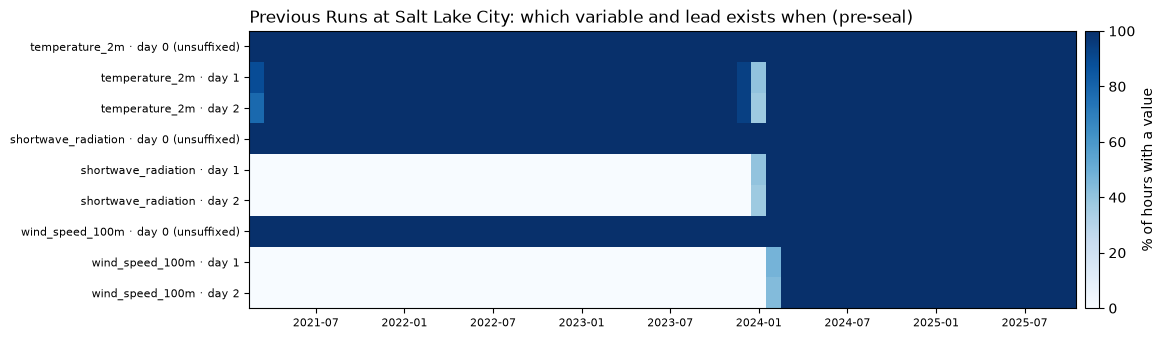

In [4]:
series = [f"{v}{s}" for v in W.BASE_VARS for s in ("", "_previous_day1", "_previous_day2")]
monthly = (pr.with_columns(pl.col("ts_utc").dt.truncate("1mo").alias("month"))
           .group_by("month").agg(*(pl.col(c).is_not_null().mean().alias(c) for c in series)).sort("month"))
grid = monthly.select(series).to_numpy().T * 100
fig, ax = plt.subplots(figsize=(11, 3.6))
im = ax.imshow(grid, aspect="auto", cmap="Blues", vmin=0, vmax=100, interpolation="nearest")
ax.set_yticks(range(len(series)), [s.replace("_previous_day", " · day ") if "previous" in s else f"{s} · day 0 (unsuffixed)"
                                   for s in series], fontsize=8)
months = monthly["month"].to_list()
ticks = [i for i, m in enumerate(months) if m.month in (1, 7)]
ax.set_xticks(ticks, [f"{months[i]:%Y-%m}" for i in ticks], fontsize=8)
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01).set_label("% of hours with a value")
ax.set_title("Previous Runs at Salt Lake City: which variable and lead exists when (pre-seal)", loc="left")
plt.show()

In [5]:
def null_runs(df: pl.DataFrame, col: str) -> pl.DataFrame:
    # Runs of consecutive null hours after the column's first value.
    first = df.filter(pl.col(col).is_not_null())["ts_utc"].min()
    d = df.filter(pl.col("ts_utc") >= first).select("ts_utc", pl.col(col).is_null().alias("null"))
    d = d.with_columns((pl.col("null") != pl.col("null").shift(1)).fill_null(True).cum_sum().alias("run"))
    return (d.filter(pl.col("null")).group_by("run")
            .agg(pl.col("ts_utc").min().alias("from"), pl.col("ts_utc").max().alias("to"), pl.len().alias("hours"))
            .drop("run").sort("hours", descending=True))

for col in ("temperature_2m_previous_day2", "shortwave_radiation_previous_day2", "wind_speed_100m_previous_day2"):
    first = pr.filter(pl.col(col).is_not_null())["ts_utc"].min()
    runs = null_runs(pr, col)
    longest = runs.row(0, named=True) if runs.height else None
    print(f"{col}: first value {first:%Y-%m-%d %H:%M}Z; null hours after that {runs['hours'].sum()}; longest gap "
          + (f"{longest['from']:%Y-%m-%d %H:%M}Z to {longest['to']:%Y-%m-%d %H:%M}Z ({longest['hours']} h)" if longest else "none"))

temperature_2m_previous_day2: first value 2021-03-24 23:00Z; null hours after that 516; longest gap 2023-12-29 23:00Z to 2024-01-20 10:00Z (516 h)
shortwave_radiation_previous_day2: first value 2024-01-20 11:00Z; null hours after that 0; longest gap none
wind_speed_100m_previous_day2: first value 2024-02-17 05:00Z; null hours after that 0; longest gap none


**What the heatmap and gap check show.** Day 0 (the unsuffixed series) is always there. Temperature day 1 and day 2 run from March 2021, with one hole of about three weeks around New Year 2024. Solar radiation and wind day 1/day 2 appear only from early 2024. So a strictly honest weather model has all three inputs only from 2024-03-01: eight months of training before the validation year starts (2024-11-01). That is why the primary model is weather-free (long history), and a weather-augmented model is compared against it on validation (decision D-025).

## 3. Lead matters

If day-ahead and nowcast weather were nearly the same, the leak would be harmless. They are not. Below, the day-1 and day-2 forecasts at Salt Lake City are compared with the day-0 series (the 0–5 h stitch, the closest this archive gets to what happened) over 2024-03-01 to 2025-10-31, when all three leads exist.

In [6]:
win = pr.filter(pl.col("ts_utc") >= datetime(2024, 3, 1, tzinfo=UTC))
rows = []
for v in W.BASE_VARS:
    for n in (1, 2):
        d = win.drop_nulls([v, f"{v}_previous_day{n}"])
        rows.append({"variable": v, "lead": f"day {n}", "hours": d.height,
                     "MAE_vs_day0": round(float((d[f"{v}_previous_day{n}"] - d[v]).abs().mean()), 2),
                     "bias_vs_day0": round(float((d[f"{v}_previous_day{n}"] - d[v]).mean()), 2)})
lead_err = pl.DataFrame(rows)
lead_err

variable,lead,hours,MAE_vs_day0,bias_vs_day0
"""temperature_2m""","""day 1""",14640,1.23,-0.05
"""temperature_2m""","""day 2""",14640,2.06,1.15
"""shortwave_radiation""","""day 1""",14640,28.05,-2.5
"""shortwave_radiation""","""day 2""",14640,32.93,0.93
"""wind_speed_100m""","""day 1""",14640,1.01,-0.01
"""wind_speed_100m""","""day 2""",14640,1.22,-0.02


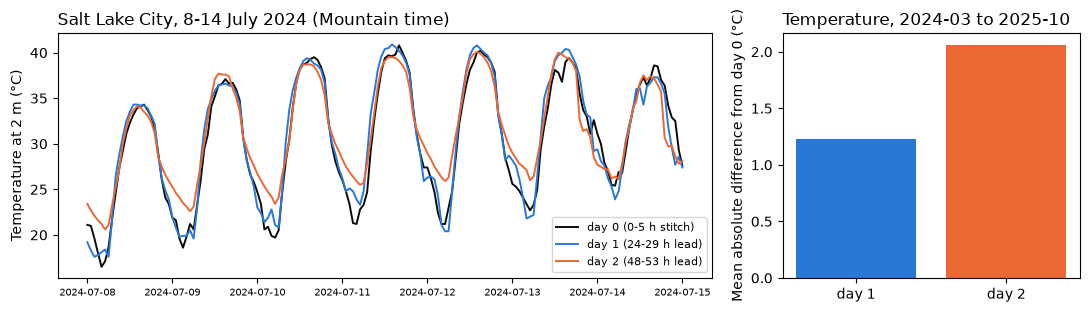

In [7]:
wk = pr.filter(pl.col("ts_utc").is_between(datetime(2024, 7, 8, 6, tzinfo=UTC), datetime(2024, 7, 15, 6, tzinfo=UTC)))
t = wk["ts_utc"].dt.convert_time_zone("America/Denver").dt.replace_time_zone(None).to_numpy()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), gridspec_kw={"width_ratios": [2.2, 1]})
for col, label, color in (("temperature_2m", "day 0 (0-5 h stitch)", "#0b0b0b"),
                          ("temperature_2m_previous_day1", "day 1 (24-29 h lead)", "#2a78d6"),
                          ("temperature_2m_previous_day2", "day 2 (48-53 h lead)", "#eb6834")):
    axes[0].plot(t, wk[col], color=color, lw=1.4, label=label)
axes[0].set_ylabel("Temperature at 2 m (°C)")
axes[0].set_title("Salt Lake City, 8-14 July 2024 (Mountain time)", loc="left")
axes[0].legend(fontsize=8)
axes[0].tick_params(axis="x", labelsize=7.5)
temp = lead_err.filter(pl.col("variable") == "temperature_2m")
axes[1].bar(temp["lead"], temp["MAE_vs_day0"], color=["#2a78d6", "#eb6834"])
axes[1].set_ylabel("Mean absolute difference from day 0 (°C)")
axes[1].set_title("Temperature, 2024-03 to 2025-10", loc="left")
fig.tight_layout()
plt.show()

**What the figure shows.** On the left, the three temperature series for one summer week track each other but part ways on individual days; the longer the lead, the larger the misses. On the right, the average gap from day 0 grows from day 1 to day 2, and the table shows the same pattern for radiation and wind. A model trained on day-0 weather would learn on better inputs than it gets at issue time. If the spec chooses to train on the Historical Forecast (option (c)), it must measure that skew on validation by scoring the same model with both feature sources.

## 4. `safe_previous_day`: choosing the lead automatically

`_previous_dayN` at Open-Meteo label t comes from a run started no later than t − 24·N h, and that run is published about `latency_h` later (Open-Meteo: "typically 4–6 hours for global models"). It was knowable at issue time I if t − 24·N h ≤ I − latency. `safe_previous_day` returns the smallest such N.

The table applies it to PACE's day-ahead case: an issue time of 10:00 Mountain time on D−1, for each local hour of D, on a summer day (MDT) and a winter day (MST), with the default 6 h latency. It passes the Open-Meteo label, which is the *end* of the hour.

In [8]:
DENVER = ZoneInfo("America/Denver")
rows = []
for d in (date(2025, 7, 15), date(2025, 1, 15)):
    issue = datetime(d.year, d.month, d.day, 10, tzinfo=DENVER) - timedelta(days=1)
    for h in range(24):
        start = datetime(d.year, d.month, d.day, h, tzinfo=DENVER)
        label = (start + timedelta(hours=1)).astimezone(UTC)
        rows.append({"day_D": str(d), "local_hour": h, "label_utc": f"{label:%Y-%m-%d %H:%M}",
                     "N": W.safe_previous_day(label, issue.astimezone(UTC))})
safe = pl.DataFrame(rows)
(safe.group_by("day_D", "N").agg(pl.col("local_hour").min().alias("first_local_hour"),
                                 pl.col("local_hour").max().alias("last_local_hour"), pl.len().alias("hours"))
 .sort("day_D", "N", descending=[True, False]))

day_D,N,first_local_hour,last_local_hour,hours
"""2025-07-15""",1,0,3,4
"""2025-07-15""",2,4,23,20
"""2025-01-15""",1,0,3,4
"""2025-01-15""",2,4,23,20


In [9]:
rows = []
for issue_h in (6, 8, 10, 12, 14):
    d = date(2025, 7, 15)
    issue = (datetime(d.year, d.month, d.day, issue_h, tzinfo=DENVER) - timedelta(days=1)).astimezone(UTC)
    ns = [W.safe_previous_day((datetime(d.year, d.month, d.day, h, tzinfo=DENVER) + timedelta(hours=1)).astimezone(UTC), issue)
          for h in range(24)]
    rows.append({"issue_time_MT_on_D-1": f"{issue_h:02d}:00", **{f"hours_needing_day{n}": ns.count(n) for n in (1, 2, 3)}})
pl.DataFrame(rows)

issue_time_MT_on_D-1,hours_needing_day1,hours_needing_day2,hours_needing_day3
"""06:00""",0,24,0
"""08:00""",2,22,0
"""10:00""",4,20,0
"""12:00""",6,18,0
"""14:00""",8,16,0


**What the tables show.** At 10:00 MT on D−1, the day-1 forecast is already published for local hours 00–03 of D, and the day-2 forecast is needed for hours 04–23, in summer and in winter. An earlier issue time needs day 2 for more hours (all 24 at 06:00 MT); a later one can use day 1 for more of the early hours (8 at 14:00 MT). Day 3 is never needed for a D−1 issue. Every weather feature at validation and test must come through this function, never from the unsuffixed or Historical Forecast values.

## 5. Sealed window: completeness only

For the 17 primary points, the sealed window is checked only for rows and null counts per variable. No value is read out.

In [10]:
def sealed_completeness() -> pl.DataFrame:
    df = W.load("previous-runs", point_ids=P1, include_sealed=True).filter(pl.col("ts_utc") >= TEST_START)
    vcols = [c for c in df.columns if c not in ("point_id", "ba", "ts_utc", "valid_time_utc")]
    return df.select(pl.len().alias("rows"), pl.col("point_id").n_unique().alias("points"),
                     pl.col("ts_utc").n_unique().alias("distinct_hours"),
                     pl.sum_horizontal(*(pl.col(c).null_count() for c in vcols)).alias("null_values_all_9_variables"))


def pre_seal_completeness() -> pl.DataFrame:
    df = W.load("previous-runs", point_ids=P1).filter(pl.col("ts_utc") >= datetime(2024, 3, 1, tzinfo=UTC))
    vcols = [c for c in df.columns if c not in ("point_id", "ba", "ts_utc", "valid_time_utc")]
    return df.select(pl.len().alias("rows"), pl.sum_horizontal(*(pl.col(c).null_count() for c in vcols))
                     .alias("null_values_all_9_variables"))


print("sealed window, 17 primary points (counts only):")
display(sealed_completeness())
print("2024-03-01 to 2025-10-31, same points:")
display(pre_seal_completeness())

sealed window, 17 primary points (counts only):


rows,points,distinct_hours,null_values_all_9_variables
146863,17,8639,0


2024-03-01 to 2025-10-31, same points:


rows,null_values_all_9_variables
248880,0


**What the counts show.** The honest archive is complete where it matters: no nulls in any of the nine series across the 17 points, both in the sealed window and in the 20 months before it from 2024-03.

## 6. Inputs re-checked

In [11]:
after = nb.inventory_digest(nb.file_inventory(files))
assert after == DIGEST, "an input file changed while the notebook ran"
print("inputs unchanged:", after == DIGEST)

inputs unchanged: True


## Decisions this supports

From the [decision log](../docs/decisions.md):
- **D-025**: honest weather comes only from Previous Runs `_previous_day2` (and `_previous_day1` where `safe_previous_day` allows it); the primary model is weather-free; a weather-augmented model is compared on validation (§1–§4).
- **D-026**: the Historical Forecast download was stopped at 6 of 17 points, and the honest Previous Runs set was extended instead (§0, §1).
- **D-006**: the sealed window is touched only for completeness (§5).